## Versão Simplificada - Listagem das Datas sem Visualização dos Quicklooks

In [1]:
import os

import geopandas as gpd
from shapely.geometry import shape
import rasterio as rio
from rasterio import Affine
from rasterio.crs import CRS
import rasterio.mask
import pystac_client
import ipywidgets as widgets
from IPython.display import display
from datetime import datetime
import time
from shapely.ops import unary_union
import matplotlib.pyplot as plt
import warnings
#from osgeo import gdal
warnings.filterwarnings("ignore")
print('Bibliotecas Importadas!!!')

Bibliotecas Importadas!!!


In [ ]:
import os

from datetime import datetime
import ipywidgets as widgets
from IPython.display import display

# Diretório base fixo
dir_saida = os.path.expanduser('~')

# ---------------- Widgets ----------------
boundobt = widgets.BoundedIntText(value=227, max=260, step=1, description='Órbita:')
boundpto = widgets.BoundedIntText(value=72, min=50, max=80, step=1, description='Ponto:')
boundano = widgets.BoundedIntText(value=2025, min=2013, max=2026, step=1, description='Ano:')

btn_criar = widgets.Button(
    description="Criar Diretórios",
    button_style='success',
    layout=widgets.Layout(width='200px')
)

out = widgets.Output()

# ---------------- Layout ----------------
print('Selecione a Órbita/Ponto e Ano:')
display(widgets.HBox([boundobt, boundpto, boundano]))
display(btn_criar)
display(out)

# ---------------- Função ----------------
def criar_diretorios(b):
    
    global dir_base, dir_raster, dir_raster_rgb, dir_raster_mask,dir_raster_inp, dir_raster_out, dir_index,dir_gpk, dir_csv, dir_param
    
    with out:
        out.clear_output()

        obt = boundobt.value
        pto = boundpto.value
        ano = boundano.value

        inp_path_row = f"{obt}_0{pto}"

        # Diretórios
        dir_base = os.path.join(dir_saida, inp_path_row, str(ano))
        dir_raster = os.path.join(dir_base, "raster")
        dir_raster_rgb = os.path.join(dir_raster, "rgb")
        dir_raster_mask = os.path.join(dir_raster, "mascaras")
        dir_raster_inp = os.path.join(dir_raster, "qmd_inp")
        dir_raster_out = os.path.join(dir_raster, "qmd_out")
        dir_index = os.path.join(dir_raster, "indices")
        dir_gpk = os.path.join(dir_base, "gpk")
        dir_csv = os.path.join(dir_base, "csv")
        dir_param = os.path.join(dir_base, "parametros")

        # Criação
        for d in [
            dir_base, dir_raster, dir_raster_rgb, dir_raster_mask,
            dir_raster_inp, dir_raster_out, dir_index,
            dir_gpk, dir_csv, dir_param
        ]:
            os.makedirs(d, exist_ok=True)

        print('-------------------------------------------------------------')
        print('ESTRUTURA DE DIRETÓRIO CRIADA')
        print('Caminho:' + dir_saida)
        print(f'Órbita/Ponto: {inp_path_row} | Ano: {ano}')
        print('-------------------------------------------------------------')

# ---------------- Conectar botão ----------------
btn_criar.on_click(criar_diretorios)

Selecione a Órbita/Ponto e Ano:


Button(button_style='success', description='Criar Diretórios', layout=Layout(width='200px'), style=ButtonStyle…

Output()

##  Buscando as imagens disponíveis no BDC

In [3]:
import pandas as pd
import numpy as np
import os
import pystac_client
from typing import List, Dict
import ipywidgets as widgets
from IPython.display import display
from PIL import Image
import rasterio
from rasterio.enums import Resampling
from tqdm.notebook import tqdm

DEBUG = False

def log_message(message: str):
    if DEBUG:
        print(f"[DEBUG] {message}")
    else:
        print(message)

# =========================================================
# 🔥 THUMBNAIL (SEM VRT)
# =========================================================
def create_thumbnail_simple(item, dir_thumb, size=400):

    os.makedirs(dir_thumb, exist_ok=True)
    thumb_path = os.path.join(dir_thumb, f"{item.id}.png")

    if not os.path.exists(thumb_path):

        bands = ["swir22", "nir08", "red"]  # falso color (igual seu padrão)

        arrays = []

        for b in bands:
            url = item.assets[b].href

            with rasterio.open(url) as src:
                data = src.read(
                    1,
                    out_shape=(size, size),
                    resampling=Resampling.bilinear
                )
                arrays.append(data)

        rgb = np.stack(arrays, axis=-1).astype("float32")

        p1, p99 = np.percentile(rgb, (1, 99))
        rgb = np.clip((rgb - p1) / (p99 - p1), 0, 1)

        rgb = (rgb * 255).astype(np.uint8)

        img = Image.fromarray(rgb)
        img.save(thumb_path)

    return thumb_path


# =========================================================
# 🔥 STAC
# =========================================================
def connect_to_stac(url: str) -> pystac_client.Client:
    try:
        client = pystac_client.Client.open(url)
        log_message(f"Conectado ao STAC: {url}")
        return client
    except Exception as e:
        log_message(f"Erro ao conectar ao STAC: {e}")
        return None


def search_items(client, tile, tile2, start_date, end_date, collections, limit=5000):
    try:
        datetime_range = f"{start_date}/{end_date}"

        item_search = client.search(
            collections=collections,
            datetime=datetime_range,
            query={"bdc:tiles": {"eq": tile}},
            max_items=limit
        )

        try:
            items = list(item_search.get_all_items())[::-1]
        except AttributeError:
            item_collection = item_search.item_collection()
            items = item_collection.items if item_collection else []

        log_message(f"Encontrados {len(items)} itens para {tile2}")

        # 🔥 ordenar por nuvem (melhores primeiro)
        items = sorted(items, key=lambda x: x.properties.get("eo:cloud_cover", 100))

        return items

    except Exception as e:
        log_message(f"Erro ao buscar itens: {e}")
        return []


# =========================================================
# 🔥 DATAFRAME
# =========================================================
def items_to_dataframe(items, colecao, tile, ano, dir_csv):

    if not items:
        return pd.DataFrame()

    lista_data = []
    lista_cenas = []
    lista_cenaid = []
    lista_nuvem = []
    lista_categ = []

    for item in items:
        props = item.properties
        cenaid = item.id

        partes = cenaid.split("_")
        cena = "_".join(partes[:4])
        categ = partes[-1] if len(partes) > 1 else colecao

        lista_data.append(props.get("datetime", "")[:10])
        lista_cenaid.append(cenaid)
        lista_cenas.append(cena)
        lista_nuvem.append(props.get("eo:cloud_cover", np.nan))
        lista_categ.append(categ)

    df = pd.DataFrame({
        "datapas": lista_data,
        "cena": lista_cenas,
        "cenaid": lista_cenaid,
        "pct_nuvem": lista_nuvem,
        "categ_coll": lista_categ
    })

    os.makedirs(dir_csv, exist_ok=True)
    df.to_csv(f"{dir_csv}/{colecao}_{tile}_{ano}.csv", index_label="id")

    return df


# =========================================================
# 🔥 EXECUÇÃO
# =========================================================
client = connect_to_stac("https://data.inpe.br/bdc/stac/v1/")

obt = boundobt.value
pto = boundpto.value
ano = boundano.value

inp_path_row = f"{obt}0{pto}"
inp_path_row_1 = f"{obt}_{pto:03d}"

start_date = f"{ano}-01-01"
end_date = f"{ano}-12-31"

collections = ["landsat-2"]

dir_thumb = os.path.join(dir_csv, "thumbnails")

dfs = []
widgets_list = []

for colecao in collections:

    items = search_items(client, inp_path_row, inp_path_row_1, start_date, end_date, [colecao])

    df = items_to_dataframe(items, colecao, inp_path_row, ano, dir_csv)
    if not df.empty:
        dfs.append(df)
    
    # =====================================================
    # 🔥 INFORMA STATUS DOS THUMBNAILS
    # =====================================================
    if items:
    
        total = min(len(items), 50)
    
        existentes = sum(
            os.path.exists(os.path.join(dir_thumb, f"{item.id}.png"))
            for item in items[:50]
        )
    
        faltantes = total - existentes
    
        if faltantes > 0:
            log_message(
                f"Verificando thumbnails... "
                f"{existentes} já existentes e "
                f"{faltantes} para gerar."
            )
        else:
            log_message(
                f"Todos os {total} thumbnails já existem."
            )

    # =====================================================
    # 🔥 THUMBNAIL + VISUAL
    # =====================================================
    # for item in items[:50]:  # ⚠️ limite pra performance
    for item in tqdm(
        items[:50],
        total=min(len(items), 50),
        desc="Gerando thumbnails"
        ):    

        data = item.properties.get("datetime", "")[:10]
        cloud = item.properties.get("eo:cloud_cover", np.nan)

        try:
            thumb = create_thumbnail_simple(item, dir_thumb)

            img = widgets.Image(
                value=open(thumb, "rb").read(),
                format='png',
                width=120
            )

            label = widgets.Label(f"{data} | ☁ {cloud:.1f}%")

            linha = widgets.HBox([img, label])
            widgets_list.append(linha)

        except Exception as e:
            print(f"Erro thumbnail {item.id}: {e}")


# =========================================================
# 🔥 OUTPUT
# =========================================================
if dfs:
    tabela_combinada = pd.concat(dfs, ignore_index=True).dropna().reset_index(drop=True)
    tabela_combinada.to_csv(f"{dir_csv}/tabela_combinada_{inp_path_row}_{ano}.csv", index_label="id")
    log_message("Tabela combinada salva com sucesso!")
    log_message("Thumnail gerado com sucesso!")
    display(tabela_combinada)

# if widgets_list:
#     display(widgets.VBox(widgets_list))

Conectado ao STAC: https://data.inpe.br/bdc/stac/v1/
Encontrados 45 itens para 226_072
Verificando thumbnails... 0 já existentes e 45 para gerar.


Gerando thumbnails:   0%|          | 0/45 [00:00<?, ?it/s]

Tabela combinada salva com sucesso!
Thumnail gerado com sucesso!


,datapas,cena,cenaid,pct_nuvem,categ_coll
0,2025-05-22,LC09_L2SP_226072_20250522,LC09_L2SP_226072_20250522_20250523_02_T1,0.00,T1
1,2025-07-09,LC09_L2SP_226072_20250709,LC09_L2SP_226072_20250709_20250711_02_T1,0.00,T1
2,2025-10-05,LC08_L2SP_226072_20251005,LC08_L2SP_226072_20251005_20251115_02_T1,0.00,T1
3,2025-07-25,LC09_L2SP_226072_20250725,LC09_L2SP_226072_20250725_20250727_02_T1,0.01,T1
4,2025-08-18,LC08_L2SP_226072_20250818,LC08_L2SP_226072_20250818_20250821_02_T1,0.66,T1
5,2025-06-07,LC09_L2SP_226072_20250607,LC09_L2SP_226072_20250607_20250608_02_T1,0.72,T1
6,2025-05-14,LC08_L2SP_226072_20250514,LC08_L2SP_226072_20250514_20250529_02_T1,1.01,T1
7,2025-09-27,LC09_L2SP_226072_20250927,LC09_L2SP_226072_20250927_20250928_02_T1,1.06,T1
8,2025-11-30,LC09_L2SP_226072_20251130,LC09_L2SP_226072_20251130_20251202_02_T1,2.42,T1
9,2025-08-10,LC09_L2SP_226072_20250810,LC09_L2SP_226072_20250810_20250811_02_T1,3.68,T1


In [4]:
def carregar_focos_periodo(item, data_inicio, data_fim):
    """
    Consulta uma única vez todos os focos do período
    dentro do BBOX da cena.

    Não aplica filtro por satélite.
    """

    # -----------------------------------------------------
    # FOOTPRINT
    # -----------------------------------------------------

    footprint = shape(item.geometry)

    if footprint.is_empty:
        return gpd.GeoDataFrame(
            {"geometry": []},
            geometry="geometry",
            crs="EPSG:4326"
        )

    minx, miny, maxx, maxy = footprint.bounds

    # -----------------------------------------------------
    # DATAS
    # -----------------------------------------------------

    inicio = f"{data_inicio}T00:00:00Z"

    data_fim_dt = datetime.strptime(
        data_fim,
        "%Y-%m-%d"
    ) + pd.Timedelta(days=1)

    fim = data_fim_dt.strftime(
        "%Y-%m-%dT00:00:00Z"
    )

    # -----------------------------------------------------
    # CONSULTA WFS
    # -----------------------------------------------------

    params = {

        "SERVICE": "WFS",

        "VERSION": "2.0.0",

        "REQUEST": "GetFeature",

        "TYPENAMES": LAYER_FOCOS,

        "OUTPUTFORMAT": "application/json",

        "CQL_FILTER": (
            f"data_hora_gmt >= '{inicio}' "
            f"AND data_hora_gmt < '{fim}' "
            f"AND BBOX("
            f"geometria,"
            f"{minx},{miny},{maxx},{maxy},"
            f"'EPSG:4326'"
            f")"
        ),

        "COUNT": 50000
    }

    print(
        f"🔎 Consultando focos de "
        f"{data_inicio} até {data_fim}..."
    )

    try:

        response = requests.get(
            WFS_URL,
            params=params,
            timeout=180
        )

        response.raise_for_status()

        geojson = response.json()

        features = geojson.get(
            "features",
            []
        )

        if not features:

            print("✓ Nenhum foco encontrado.")

            return gpd.GeoDataFrame(
                {"geometry": []},
                geometry="geometry",
                crs="EPSG:4326"
            )

        focos = gpd.GeoDataFrame.from_features(
            features
        )

        focos = gpd.GeoDataFrame(
            focos,
            geometry="geometry",
            crs="EPSG:4326"
        )

        # -------------------------------------------------
        # DATA DO FOCO
        # -------------------------------------------------

        focos["data_foco"] = pd.to_datetime(
            focos["data_hora_gmt"],
            errors="coerce"
        ).dt.strftime("%Y-%m-%d")

        print(
            f"✓ {len(focos)} focos carregados."
        )

        return focos

    except Exception as e:

        print(
            f"⚠️ Erro ao consultar focos: {e}"
        )

        return gpd.GeoDataFrame(
            {"geometry": []},
            geometry="geometry",
            crs="EPSG:4326"
        )
def obter_focos_por_cena(focos_periodo, item, data):
    """
    Retorna somente os focos da data e da cena.

    Não realiza nova consulta ao WFS.
    """

    if focos_periodo.empty:
        return focos_periodo.copy()

    # -----------------------------------------------------
    # FILTRO POR DATA
    # -----------------------------------------------------

    focos = focos_periodo[
        focos_periodo["data_foco"] == data
    ].copy()

    if focos.empty:
        return focos

    # -----------------------------------------------------
    # FILTRO PELO FOOTPRINT EXATO DA CENA
    # -----------------------------------------------------

    footprint = shape(item.geometry)

    focos = focos[
        focos.geometry.within(footprint)
    ].copy()

    return focos

📂 45 thumbnails encontrados
🔎 Consultando focos de 2025-01-06 até 2025-12-24...
✓ 6430 focos carregados.


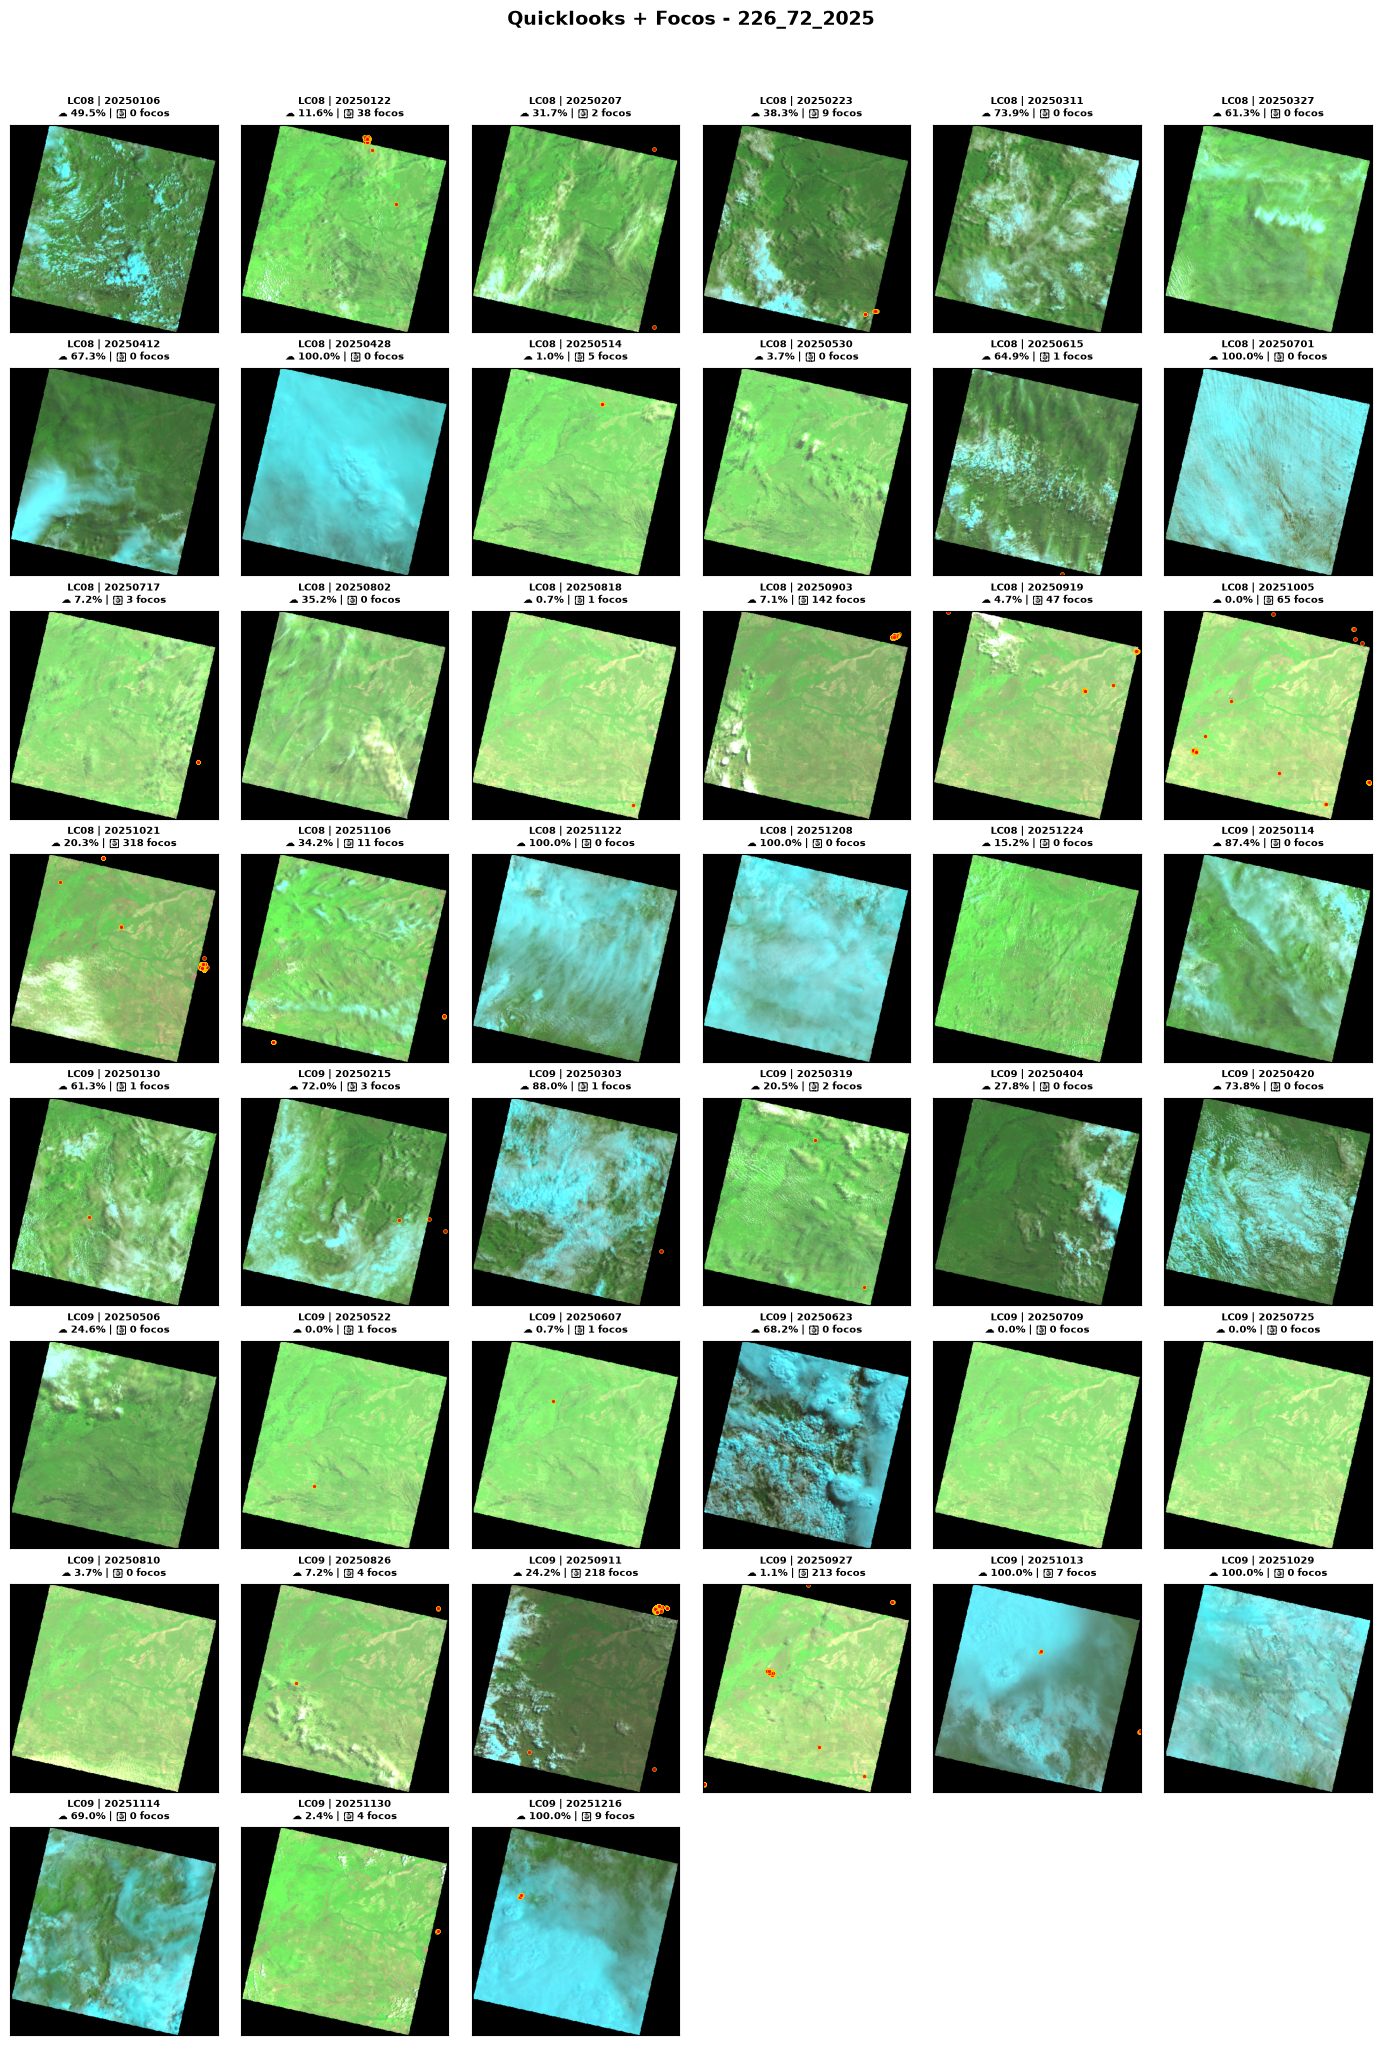

In [5]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from PIL import Image
from shapely.geometry import shape
import geopandas as gpd
import requests
from urllib.parse import urlencode
from datetime import datetime


# =========================================================
# CONFIGURAÇÃO
# =========================================================

WFS_URL = (
    "https://terrabrasilis.dpi.inpe.br/queimadas/"
    "geoserver/wfs"
)

LAYER_FOCOS = "bdqueimadas3:focos_pnt"

THUMB_SIZE = 400
COLS = 6


# =========================================================
# CACHE
# =========================================================

focos_cache = {}
stac_cache = {}


# =========================================================
# 🔥 OBTER ITEM STAC PELO ID DA CENA
# =========================================================

def obter_item_por_id(cenaid):
    """
    Recupera um item STAC diretamente pelo ID da cena.

    Exemplo:
    LC09_L2SP_227072_20250716_20250723_02_T1
    """

    if cenaid in stac_cache:
        return stac_cache[cenaid]

    try:

        search = client.search(
            collections=["landsat-2"],
            ids=[cenaid],
            max_items=1
        )

        items = list(search.items())

        if not items:

            print(
                f"⚠️ Cena não encontrada no STAC: {cenaid}"
            )

            return None

        item = items[0]

        stac_cache[cenaid] = item

        return item

    except Exception as e:

        print(
            f"⚠️ Erro ao recuperar {cenaid}: {e}"
        )

        return None


# =========================================================
# CACHE DOS FOCOS
# =========================================================

focos_cache = {}


# =========================================================
# BUSCAR FOCOS DA DATA DENTRO DA CENA
# =========================================================

def obter_focos_por_cena(focos_periodo, item, data):
    """
    Retorna somente os focos:

    - da data da cena
    - dentro do footprint exato da cena

    Não realiza nova consulta ao WFS.
    """

    # -----------------------------------------------------
    # SEM FOCOS NO PERÍODO
    # -----------------------------------------------------

    if focos_periodo.empty:
        return focos_periodo.copy()

    # -----------------------------------------------------
    # FILTRO POR DATA
    # -----------------------------------------------------

    focos = focos_periodo[
        focos_periodo["data_foco"] == data
    ].copy()

    if focos.empty:
        return focos

    # -----------------------------------------------------
    # FOOTPRINT DA CENA
    # -----------------------------------------------------

    footprint = shape(item.geometry)

    if footprint.is_empty:
        return focos.iloc[0:0].copy()

    # -----------------------------------------------------
    # GARANTIR MESMO CRS
    # -----------------------------------------------------

    if focos.crs is None:
        focos = focos.set_crs("EPSG:4326")

    elif focos.crs.to_epsg() != 4326:
        focos = focos.to_crs("EPSG:4326")

    # -----------------------------------------------------
    # FILTRO PELO FOOTPRINT EXATO
    # -----------------------------------------------------

    focos = focos[
        focos.geometry.within(footprint)
    ].copy()

    return focos

# =========================================================
# CONVERTER FOCOS PARA PIXEL DA THUMBNAIL
# =========================================================

def focos_para_thumbnail(item, focos, size=400):
    """
    Converte os focos de EPSG:4326 para o CRS do raster
    e depois para coordenadas de pixel da thumbnail.
    """

    if focos.empty:
        return [], []

    asset_url = item.assets["swir22"].href

    xs = []
    ys = []

    with rasterio.open(asset_url) as src:

        width = src.width
        height = src.height

        # -------------------------------------------------
        # CRS DO RASTER
        # -------------------------------------------------

        if src.crs is None:
            print("⚠️ Raster sem CRS definido")
            return [], []

        # -------------------------------------------------
        # CONVERTER FOCOS PARA O CRS DO RASTER
        # -------------------------------------------------

        focos_raster = focos.to_crs(src.crs)

        # -------------------------------------------------
        # CONVERTER CADA FOCO PARA PIXEL
        # -------------------------------------------------

        for geom in focos_raster.geometry:

            if geom is None or geom.is_empty:
                continue

            x_coord = geom.x
            y_coord = geom.y

            try:

                row, col = src.index(
                    x_coord,
                    y_coord
                )

                # -----------------------------------------
                # VERIFICA SE ESTÁ DENTRO DO RASTER
                # -----------------------------------------

                if (
                    col < 0
                    or col >= width
                    or row < 0
                    or row >= height
                ):
                    continue

                # -----------------------------------------
                # CONVERTE PARA TAMANHO DA THUMBNAIL
                # -----------------------------------------

                x = col * size / width
                y = row * size / height

                xs.append(x)
                ys.append(y)

            except Exception:
                continue

    return xs, ys




# =========================================================
# LIMPAR OUTPUT
# =========================================================

from IPython.display import clear_output

clear_output(wait=True)


# =========================================================
# LOCALIZAR THUMBNAILS
# =========================================================

files = sorted(
    glob.glob(
        os.path.join(
            dir_thumb,
            "*.png"
        )
    )
)

if not files:

    print("⚠️ Nenhum thumbnail encontrado")

else:

    print(
        f"📂 {len(files)} thumbnails encontrados"
    )


# =========================================================
# DICIONÁRIO CENA → % NUVEM
# =========================================================

dict_nuvem = dict(
    zip(
        tabela_combinada["cenaid"],
        tabela_combinada["pct_nuvem"]
    )
)


# =========================================================
# MONTAR GRID
# =========================================================

rows = int(
    np.ceil(
        len(files) / COLS
    )
)

fig = plt.figure(
    figsize=(
        14,
        rows * 2.5
    )
)

plt.suptitle(
    f"Quicklooks + Focos - "
    f"{boundobt.value}_{boundpto.value}_{boundano.value}",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

# =========================================================
# CARREGAR FOCOS DO PERÍODO UMA ÚNICA VEZ
# =========================================================

primeiro_nome = os.path.basename(
    files[0]
).replace(".png", "")

primeiro_item = obter_item_por_id(
    primeiro_nome
)

datas = sorted(
    tabela_combinada["datapas"].unique()
)

data_inicio_periodo = datas[0]
data_fim_periodo = datas[-1]

focos_periodo = carregar_focos_periodo(
    primeiro_item,
    data_inicio_periodo,
    data_fim_periodo
)
# =========================================================
# PROCESSAR CADA THUMBNAIL
# =========================================================

for j, file in enumerate(files):

    # -----------------------------------------------------
    # ID DA CENA
    # -----------------------------------------------------

    nome = os.path.basename(
        file
    ).replace(
        ".png",
        ""
    )

    partes = nome.split("_")

    try:

        sat = partes[0]

        # Exemplo:
        # LC09_L2SP_227072_20250716_20250723_02_T1
        data = partes[3]

        data_formatada = (
            f"{data[:4]}-"
            f"{data[4:6]}-"
            f"{data[6:8]}"
        )

    except Exception:

        sat = "UNK"
        data = None
        data_formatada = None


    # -----------------------------------------------------
    # NUVEM
    # -----------------------------------------------------

    pct_nuvem = dict_nuvem.get(
        nome,
        np.nan
    )

    if pd.isna(pct_nuvem):

        nuvem_txt = "N/A"

    else:

        nuvem_txt = (
            f"{pct_nuvem:.1f}%"
        )


    # -----------------------------------------------------
    # CRIAR EIXO
    # -----------------------------------------------------

    ax = fig.add_subplot(
        rows,
        COLS,
        j + 1
    )


    try:

        # =================================================
        # ITEM STAC
        # =================================================
        # 🔥 AGORA USAMOS O ID DA PRÓPRIA THUMBNAIL
        # =================================================

        item = obter_item_por_id(
            nome
        )

        if item is None:

            raise Exception(
                "Cena não encontrada no STAC"
            )


        # =================================================
        # IMAGEM
        # =================================================

        img = Image.open(
            file
        )

        img = img.resize(
            (
                THUMB_SIZE,
                THUMB_SIZE
            )
        )

        ax.imshow(
            img
        )


        # =================================================
        # FOCOS DA CENA
        # =================================================

        focos = obter_focos_por_cena(
            focos_periodo,
            item,
            data_formatada
        )
            

        # =================================================
        # CONVERTER FOCOS
        # =================================================

        xs, ys = focos_para_thumbnail(
            item,
            focos,
            size=THUMB_SIZE
        )


        # =================================================
        # DESENHAR FOCOS
        # =================================================

        if xs:

            ax.scatter(
                xs,
                ys,
                s=8,
                c="red",
                marker="o",
                edgecolors="yellow",
                linewidths=0.4,
                alpha=0.85
            )


        # =================================================
        # TÍTULO
        # =================================================

        titulo = (
            f"{sat} | {data}\n"
            f"☁ {nuvem_txt} | "
            f"🔥 {len(xs)} focos"
        )

        ax.set_title(
            titulo,
            fontsize=7,
            fontweight="bold"
        )


    except Exception as e:

        print(
            f"⚠️ Erro {data}: {e}"
        )

        # -------------------------------------------------
        # Mesmo com erro, mantém a thumbnail
        # -------------------------------------------------

        img = Image.open(
            file
        )

        img = img.resize(
            (
                THUMB_SIZE,
                THUMB_SIZE
            )
        )

        ax.imshow(
            img
        )

        ax.set_title(
            f"{sat} | {data}\n"
            f"☁ {nuvem_txt}",
            fontsize=7,
            fontweight="bold"
        )


    ax.set_xticks([])
    ax.set_yticks([])


# =========================================================
# FINAL
# =========================================================

plt.tight_layout()

plt.show()

In [ ]:
import io
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from PIL import Image
import os
import pandas as pd


# =========================================================
# GERAR THUMBNAIL COM FOCOS
# =========================================================

def thumbnail_com_focos(
    caminho,
    cenaid,
    data,
    tamanho=600,
    data_inicio=None
):
    """
    Gera a thumbnail com os focos.

    Comportamento:
    
    - Pré-fogo:
        mostra somente os focos da data da imagem.

    - Pós-fogo:
        mostra todos os focos entre data_inicio
        e data, inclusive.

    Os focos são sempre filtrados pelo footprint
    exato da cena correspondente.
    """

    # -----------------------------------------------------
    # ABRIR THUMBNAIL
    # -----------------------------------------------------

    img = Image.open(caminho).convert("RGB")

    # -----------------------------------------------------
    # ITEM STAC
    # -----------------------------------------------------

    item = obter_item_por_id(cenaid)

    if item is None:
        return img, 0

    # -----------------------------------------------------
    # FOCOS DA CENA
    # -----------------------------------------------------

    if data_inicio is None:

        # =================================================
        # PRÉ-FOGO
        # =================================================
        # Somente os focos da data da imagem
        # =================================================

        focos = obter_focos_por_cena(
            focos_periodo,
            item,
            data
        )

    else:

        # =================================================
        # PÓS-FOGO
        # =================================================
        # Todos os focos desde a imagem pré-fogo
        # até a imagem pós-fogo
        # =================================================

        focos = obter_focos_intervalo(
            focos_periodo,
            item,
            data_inicio,
            data
        )

    # -----------------------------------------------------
    # CONVERTER PARA PIXEL
    # -----------------------------------------------------

    xs, ys = focos_para_thumbnail(
        item,
        focos,
        size=tamanho
    )

    # -----------------------------------------------------
    # PREPARAR IMAGEM
    # -----------------------------------------------------

    img = img.resize(
        (tamanho, tamanho)
    )

    fig, ax = plt.subplots(
        figsize=(6, 6),
        dpi=100
    )

    ax.imshow(img)

    # -----------------------------------------------------
    # DESENHAR FOCOS
    # -----------------------------------------------------

    if len(xs) > 0:

        ax.scatter(
            xs,
            ys,
            s=18,
            c="red",
            marker="o",
            edgecolors="yellow",
            linewidths=0.6,
            alpha=0.9
        )

    ax.set_xticks([])
    ax.set_yticks([])

    plt.tight_layout(
        pad=0
    )

    # -----------------------------------------------------
    # CONVERTER PARA PNG
    # -----------------------------------------------------

    buffer = io.BytesIO()

    fig.savefig(
        buffer,
        format="png",
        bbox_inches="tight",
        pad_inches=0
    )

    plt.close(fig)

    buffer.seek(0)

    imagem_final = Image.open(
        buffer
    ).convert("RGB")

    buffer.close()

    return imagem_final, len(xs)


# =========================================================
# 🔥 NOVA FUNÇÃO:
# FOCOS DO INTERVALO PRÉ → PÓS
# =========================================================

def obter_focos_intervalo(
    focos_periodo,
    item,
    data_inicio,
    data_fim
):
    """
    Retorna somente os focos:

    - entre data_inicio e data_fim, inclusive;
    - dentro do footprint exato da cena.

    Não realiza nova consulta ao WFS.
    """

    # -----------------------------------------------------
    # SEM FOCOS NO PERÍODO
    # -----------------------------------------------------

    if focos_periodo.empty:
        return focos_periodo.copy()

    # -----------------------------------------------------
    # FILTRO POR INTERVALO DE DATAS
    # -----------------------------------------------------

    focos = focos_periodo[
        (focos_periodo["data_foco"] >= data_inicio) &
        (focos_periodo["data_foco"] <= data_fim)
    ].copy()

    if focos.empty:
        return focos

    # -----------------------------------------------------
    # FOOTPRINT DA CENA
    # -----------------------------------------------------

    footprint = shape(item.geometry)

    if footprint.is_empty:
        return focos.iloc[0:0].copy()

    # -----------------------------------------------------
    # GARANTIR MESMO CRS
    # -----------------------------------------------------

    if focos.crs is None:

        focos = focos.set_crs(
            "EPSG:4326"
        )

    elif focos.crs.to_epsg() != 4326:

        focos = focos.to_crs(
            "EPSG:4326"
        )

    # -----------------------------------------------------
    # FILTRO PELO FOOTPRINT EXATO
    # -----------------------------------------------------

    focos = focos[
        focos.geometry.within(footprint)
    ].copy()

    return focos


# =========================================================
# LISTA DE DATAS
# =========================================================

datas = sorted(
    tabela_combinada["datapas"].unique()
)


# =========================================================
# DROPDOWNS
# =========================================================

select_pre = widgets.Dropdown(
    options=datas,
    description="Pré-Fogo:",
    layout=widgets.Layout(
        width="300px"
    )
)

select_pos = widgets.Dropdown(
    options=datas,
    description="Pós-Fogo:",
    layout=widgets.Layout(
        width="300px"
    )
)


out = widgets.Output()


# =========================================================
# BUSCAR THUMBNAIL
# =========================================================

def get_thumb_by_date(data):

    df_filtrado = tabela_combinada[
        tabela_combinada["datapas"] == data
    ]

    if df_filtrado.empty:
        return None, None, None

    cenaid = df_filtrado.iloc[0]["cenaid"]

    nuvem = df_filtrado.iloc[0]["pct_nuvem"]

    caminho = os.path.join(
        dir_thumb,
        f"{cenaid}.png"
    )

    return caminho, cenaid, nuvem


# =========================================================
# ATUALIZAR
# =========================================================

def atualizar(change=None):

    with out:

        out.clear_output()

        # =================================================
        # PRÉ-FOGO
        # =================================================

        pre_path, pre_cenaid, pre_nuvem = get_thumb_by_date(
            select_pre.value
        )

        if (
            pre_path is not None
            and os.path.exists(pre_path)
        ):

            # -------------------------------------------------
            # PRÉ-FOGO:
            # somente focos da própria data
            # -------------------------------------------------

            imagem_pre, qtd_pre = thumbnail_com_focos(
                pre_path,
                pre_cenaid,
                select_pre.value
            )

            buffer_pre = io.BytesIO()

            imagem_pre.save(
                buffer_pre,
                format="PNG"
            )

            img_pre = widgets.Image(
                value=buffer_pre.getvalue(),
                format="png",
                width=450
            )

            texto_pre = (
                f"<h3>Pré-Fogo</h3>"
                f"<p>{select_pre.value} "
                f"| Nuvem: {pre_nuvem:.1f}% "
                f"| 🔥 {qtd_pre} focos</p>"
            )

            box_pre = widgets.VBox([
                widgets.HTML(texto_pre),
                img_pre
            ])

        else:

            box_pre = widgets.Label(
                "Sem imagem pré"
            )


        # =================================================
        # PÓS-FOGO
        # =================================================

        pos_path, pos_cenaid, pos_nuvem = get_thumb_by_date(
            select_pos.value
        )

        if (
            pos_path is not None
            and os.path.exists(pos_path)
        ):

            # -------------------------------------------------
            # PÓS-FOGO:
            # todos os focos entre pré e pós
            # -------------------------------------------------

            imagem_pos, qtd_pos = thumbnail_com_focos(
                pos_path,
                pos_cenaid,
                select_pos.value,
                data_inicio=select_pre.value
            )

            buffer_pos = io.BytesIO()

            imagem_pos.save(
                buffer_pos,
                format="PNG"
            )

            img_pos = widgets.Image(
                value=buffer_pos.getvalue(),
                format="png",
                width=450
            )

            texto_pos = (
                f"<h3>Pós-Fogo</h3>"
                f"<p>{select_pos.value} "
                f"| Nuvem: {pos_nuvem:.1f}% "
                f"| 🔥 {qtd_pos} focos "
                f"({select_pre.value} → "
                f"{select_pos.value})</p>"
            )

            box_pos = widgets.VBox([
                widgets.HTML(texto_pos),
                img_pos
            ])

        else:

            box_pos = widgets.Label(
                "Sem imagem pós"
            )


        # =================================================
        # EXIBIR
        # =================================================

        display(
            widgets.HBox([
                box_pre,
                box_pos
            ])
        )


# =========================================================
# EVENTOS
# =========================================================

select_pre.observe(
    atualizar,
    names="value"
)

select_pos.observe(
    atualizar,
    names="value"
)


# =========================================================
# EXIBIR INTERFACE
# =========================================================

display(
    widgets.VBox([
        widgets.HBox([
            select_pre,
            select_pos
        ]),
        out
    ])
)


# =========================================================
# INICIALIZAR
# =========================================================

atualizar()

In [8]:
# Função para buscar itens no STAC por tile e intervalo de datas
def search_items_by_date(client: pystac_client.Client, tile: str, tile2: str, start_date: str, end_date: str, collections: List[str], limit: int = 5000) -> List[Dict]:
    """
    Busca itens no STAC de um tile específico entre start_date e end_date.
    start_date e end_date devem estar no formato 'YYYY-MM-DD'
    """
    try:
        datetime_range = f"{start_date}/{end_date}"
        item_search = client.search(
            collections=collections,
            datetime=datetime_range,
            query={"bdc:tiles": {"eq": tile}},
            max_items=limit
        )
        try:
            # versões antigas do pystac-client
            items = list(item_search.get_all_items())[::-1]
        except AttributeError:
            # versões mais novas
            item_collection = item_search.item_collection()
            items = item_collection.items if item_collection else []

#         log_message(f"Encontrados {len(items)} itens para a órbita/Ponto {tile2} no intervalo {start_date} -> {end_date}")
        return items
    except Exception as e:
        log_message(f"Erro ao buscar itens: {e}")
        return []

def mask_image_data(qa_arr):
    """
    Gera máscara binária a partir da banda QA_PIXEL (Landsat 8/9),
    considerando apenas o bit 0 (Fill).
    Retorna array uint8 com: 1 = pixel com dados de imagem (bit 0 = 0);
    0 = pixel de preenchimento (bit 0 = 1).
    """
    qa = qa_arr.astype(np.uint16)

    # Bit 0 representa 'Fill' (0 = dado de imagem, 1 = preenchimento)
    fill = (qa >> 0) & 1

    # Pixels onde o bit de preenchimento é 1 são considerados preenchimento
    is_fill = (fill == 1)

    # Queremos uma máscara onde bit 0 == 0 (não-preenchimento), então invertemos is_fill
    mask_bin = np.where(~is_fill, 1, 0).astype(np.uint8)
    return mask_bin

def get_footprint_geom(qa_href):

    with rasterio.open(qa_href) as src_qa:
        qa = src_qa.read(1).astype("uint16")

        mask_binary = mask_image_data(qa)

        shapes_gen = rasterio.features.shapes(
            mask_binary.astype("int16"),
            transform=src_qa.transform,
            mask=mask_binary.astype(bool)
        )

        geoms = [shape(geom) for geom, val in shapes_gen if val == 1]

        if not geoms:
            return None, None

        gdf = gpd.GeoDataFrame(geometry=geoms, crs=src_qa.crs)

        # 🔥 mesma lógica do seu salvamento
        gdf = gdf.dissolve()

        geom = gdf.geometry.iloc[0]

        return geom, src_qa.crs
        
def clean_overlap(geom):

    if geom.geom_type == "GeometryCollection":
        polys = [g for g in geom.geoms if g.geom_type in ["Polygon", "MultiPolygon"]]
        
        if not polys:
            return None
        
        geom = unary_union(polys)

    # garante geometria válida
    geom = geom.buffer(0)

    return geom

def qa_mask_to_binary(qa_arr, cloud_conf_thresh=2, shadow_conf_thresh=2, snow_conf_thresh=2):
    """
    Gera máscara binária a partir da banda QA_PIXEL (Landsat 8/9).
    Retorna array uint8 com: 1 = pixel livre de contaminação; 0 = pixel contaminado.
    Parâmetros de confiança: 0..3 (0=none,1=low,2=medium,3=high).
    """
    qa = qa_arr.astype(np.uint16)

    # bits individuais
    fill = (qa >> 0) & 1
    dilated = (qa >> 1) & 1
    cirrus = (qa >> 2) & 1
    cloud = (qa >> 3) & 1
    cloud_shadow = (qa >> 4) & 1
    snow = (qa >> 5) & 1
    # clear = (qa >> 6) & 1   # não usado diretamente
    # water = (qa >> 7) & 1   # opcional

    # confidences (2 bits cada)
    cloud_conf = (qa >> 8) & 0b11
    shadow_conf = (qa >> 10) & 0b11
    snow_conf = (qa >> 12) & 0b11
    cirrus_conf = (qa >> 14) & 0b11

    # condições que definem contaminação
    is_fill = fill == 1
    is_cloud = (cloud == 1) | (dilated == 1) | (cloud_conf >= cloud_conf_thresh)
    is_shadow = (cloud_shadow == 1) | (shadow_conf >= shadow_conf_thresh)
    is_snow = (snow == 1) | (snow_conf >= snow_conf_thresh)
    is_cirrus = (cirrus == 1) | (cirrus_conf >= cloud_conf_thresh)

    contaminated = is_fill | is_cloud | is_shadow | is_snow | is_cirrus

    # máscara binária: 1 = limpo, 0 = contaminado
    mask_bin = np.where(~contaminated, 1, 0).astype(np.uint8)
    return mask_bin

In [9]:
from datetime import timedelta
import rasterio as rio

# Datas selecionadas
data_pre = select_pre.value
data_pos = select_pos.value

# Converte para datetime
# data_pre_dt = pd.to_datetime(data_pre, format="%Y%m%d")
# data_pos_dt = pd.to_datetime(data_pos, format="%Y%m%d")

data_pre_dt = pd.to_datetime(data_pre)
data_pos_dt = pd.to_datetime(data_pos)

# Intervalos ±1 dia
inicial_pre = (data_pre_dt - timedelta(days=1)).strftime("%Y-%m-%d")
final_pre   = (data_pre_dt + timedelta(days=1)).strftime("%Y-%m-%d")

inicial_pos = (data_pos_dt - timedelta(days=1)).strftime("%Y-%m-%d")
final_pos   = (data_pos_dt + timedelta(days=1)).strftime("%Y-%m-%d")

data_pre=data_pre.replace('-', '')
data_pos=data_pos.replace('-', '')

# -------------------------
# BUSCA STAC
# -------------------------
items_pre = search_items_by_date(client, inp_path_row, inp_path_row, inicial_pre, final_pre, ["landsat-2"])
image_pre = items_pre[0] if items_pre else None

items_pos = search_items_by_date(client, inp_path_row, inp_path_row, inicial_pos, final_pos, ["landsat-2"])
image_pos = items_pos[0] if items_pos else None

print("Pré-fogo:", image_pre.id if image_pre else "Nenhuma")
print("Pós-fogo:", image_pos.id if image_pos else "Nenhuma")


# -------------------------
# ASSETS
# -------------------------
assets_pre = image_pre.assets
assets_pos = image_pos.assets


# -------------------------
# CRS (referência)
# -------------------------
with rio.open(assets_pre['blue'].href) as ds:
    crs_ref = ds.crs

# -------------------------
# FOOTPRINTS
# -------------------------
footprint_pre, crs_pre = get_footprint_geom(assets_pre['qa_pixel'].href)
footprint_pos, crs_pos = get_footprint_geom(assets_pos['qa_pixel'].href)

if crs_pre != crs_pos:
    raise ValueError("CRS diferente entre pré e pós")


# -------------------------
# OVERLAP (GEOMETRIA FINAL)
# -------------------------
overlap = footprint_pre.intersection(footprint_pos)

aoi_geom = clean_overlap(overlap)

if aoi_geom is None or aoi_geom.is_empty:
    raise ValueError("Overlap inválido")

print("AOI pronta:", aoi_geom.geom_type)

Pré-fogo: LC08_L2SP_226072_20251021_20251120_02_T1
Pós-fogo: LC09_L2SP_226072_20251029_20251104_02_T2
AOI pronta: Polygon


In [10]:
t0 = time.time()

from rasterio.warp import reproject, Resampling

# ============================================
# FUNÇÕES
# ============================================

def read_band_aligned(asset, ref_shape, ref_transform, ref_crs, scale=True):
    with rio.open(asset) as src:
        data = src.read(1).astype("float32")

        if scale:
            data = data * 0.0000275 - 0.2

        aligned = np.empty(ref_shape, dtype="float32")

        reproject(
            source=data,
            destination=aligned,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            resampling=Resampling.bilinear
        )

        return aligned


def read_qa_aligned(asset, ref_shape, ref_transform, ref_crs):
    with rio.open(asset) as src:
        data = src.read(1).astype(np.uint16)

        aligned = np.zeros(ref_shape, dtype=np.uint16)

        reproject(
            source=data,
            destination=aligned,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            resampling=Resampling.nearest  # 🔥 IMPORTANTÍSSIMO
        )

        return aligned


def read_band(asset, window, mask):
    with rio.open(asset) as src:
        arr = src.read(1, window=window) * 0.0000275 - 0.2
        arr[mask] = np.nan
        return arr


def apply_mask(arr, mask):
    arr = arr.copy()
    arr[~mask] = np.nan
    return arr


# ============================================
# PRÉ-FOGO (REFERÊNCIA)
# ============================================

print('\ninicio da leitura das imagens pré-fogo\n')

with rio.open(assets_pre['red'].href) as ref:

    aoi = [aoi_geom.buffer(0)]

    mask, transform, window = rasterio.mask.raster_geometry_mask(
        ref,
        aoi,
        crop=True
    )

    crs = ref.crs

    b4_pre = ref.read(1, window=window) * 0.0000275 - 0.2
    b4_pre[mask] = np.nan

    shape = b4_pre.shape

    # 🔥 QA PRÉ
    with rio.open(assets_pre['qa_pixel'].href) as src:
        qa_pre = src.read(1, window=window).astype(np.uint16)
        qa_pre[mask] = 0


# -------------------------
# BANDAS PRÉ
# -------------------------
# b2_pre = read_band(assets_pre['blue'].href, window, mask)
b3_pre = read_band(assets_pre['green'].href, window, mask)
b5_pre = read_band(assets_pre['nir08'].href, window, mask)
b6_pre = read_band(assets_pre['swir16'].href, window, mask)
b7_pre = read_band(assets_pre['swir22'].href, window, mask)


# ============================================
# PÓS-FOGO (ALINHADO AO PRÉ)
# ============================================

print('inicio da leitura das imagens pós-fogo\n')

# b2_pos = read_band_aligned(assets_pos['blue'].href, shape, transform, crs)
b3_pos = read_band_aligned(assets_pos['green'].href, shape, transform, crs)
b4_pos = read_band_aligned(assets_pos['red'].href, shape, transform, crs)
b5_pos = read_band_aligned(assets_pos['nir08'].href, shape, transform, crs)
b6_pos = read_band_aligned(assets_pos['swir16'].href, shape, transform, crs)
b7_pos = read_band_aligned(assets_pos['swir22'].href, shape, transform, crs)

# aplica AOI
# b2_pos[mask] = np.nan
b3_pos[mask] = np.nan
b4_pos[mask] = np.nan
b5_pos[mask] = np.nan
b6_pos[mask] = np.nan
b7_pos[mask] = np.nan


# ============================================
# QA PÓS (ALINHADO)
# ============================================

qa_pos = read_qa_aligned(
    assets_pos['qa_pixel'].href,
    shape,
    transform,
    crs
)

qa_pos[mask] = 0


# ============================================
# MÁSCARA FINAL
# ============================================

mask_pre = qa_mask_to_binary(qa_pre)
mask_pos = qa_mask_to_binary(qa_pos)

mask_common = (mask_pre == 1) & (mask_pos == 1)


# ============================================
# APLICAR MÁSCARA NAS BANDAS
# ============================================

# PRÉ
# b2_pre = apply_mask(b2_pre, mask_common)
b3_pre = apply_mask(b3_pre, mask_common)
b4_pre = apply_mask(b4_pre, mask_common)
b5_pre = apply_mask(b5_pre, mask_common)
b6_pre = apply_mask(b6_pre, mask_common)
b7_pre = apply_mask(b7_pre, mask_common)

# PÓS
# b2_pos = apply_mask(b2_pos, mask_common)
b3_pos = apply_mask(b3_pos, mask_common)
b4_pos = apply_mask(b4_pos, mask_common)
b5_pos = apply_mask(b5_pos, mask_common)
b6_pos = apply_mask(b6_pos, mask_common)
b7_pos = apply_mask(b7_pos, mask_common)


# ============================================
# TEMPO
# ============================================

t1 = time.time()
hours, rem = divmod(t1 - t0, 3600)
minutes, seconds = divmod(rem, 60)

print(f"Tempo Estimado no BDC : {int(hours):02}:{int(minutes):02}:{seconds:05.2f}\n")


inicio da leitura das imagens pré-fogo

inicio da leitura das imagens pós-fogo

Tempo Estimado no BDC : 00:10:34.44



## Verificação da máscara de nuvem (opcional)

In [ ]:
# plt.figure(figsize=(15,5))

# plt.subplot(1,3,1)
# plt.imshow(mask_pre, cmap="gray")
# plt.title("QA PRE")

# plt.subplot(1,3,2)
# plt.imshow(mask_pos, cmap="gray")
# plt.title("QA POS")

# plt.subplot(1,3,3)
# plt.imshow(mask_common, cmap="gray")
# plt.title("QA COMMON")

# plt.show()

## Função para salvar a máscara de nuvem no formato geotiff (opcional)

In [22]:
def save_mask(mask, transform, crs, path):

    mask = mask.astype("uint8")

    with rasterio.open(
        path,
        "w",
        driver="GTiff",
        height=mask.shape[0],
        width=mask.shape[1],
        count=1,
        dtype="uint8",
        crs=crs,
        transform=transform,
        nodata=0,
        compress="deflate"
    ) as dst:
        dst.write(mask, 1)

    print(f"Cloud Mask salva: {path}")

In [23]:
# save_mask(mask_pre, transform, crs, f"{dir_raster_mask}/{inp_path_row_1}_{data_pre}_cloud_mask.tif)
# save_mask(mask_pos, transform, crs, f"{dir_raster_mask}/{inp_path_row_1}_{data_pos}_cloud_mask.tif)
save_mask(mask_common, transform, crs, f"{dir_raster_mask}/{inp_path_row_1}_{data_pre}_{data_pos}_cloud_mask.tif")

Cloud Mask salva: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/mascaras/227_065_20240705_20240713_cloud_mask.tif


##  Função para salvar o raster das bandas separadas ou dos índices espectrais (opcional)

In [13]:
def save_raster(array, transform, crs, path):

    array = array.astype("float32")

    with rasterio.open(
        path,
        "w",
        driver="GTiff",
        height=array.shape[0],
        width=array.shape[1],
        count=1,
        dtype="float32",
        crs=crs,
        transform=transform,
        nodata=np.nan,
        compress="deflate"
    ) as dst:
        dst.write(array, 1)

    print(f"Salvo: {path}")

## Salvar as bandas espectrais - Opcional

In [14]:
save_raster(b5_pre, transform, crs, f"{dir_index}/{inp_path_row_1}_{data_pre}_b5.tif")
save_raster(b5_pos, transform, crs, f"{dir_index}/{inp_path_row_1}_{data_pos}_b5.tif")


Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240705_b5.tif
Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240713_b5.tif


## Salvar a composição RGB (b7,b5,b4) - Opcional

In [13]:
# # stack composição rgb
# rgb_pre = np.dstack([b7_pre, b5_pre, b4_pre])
# rgb_pos = np.dstack([b7_pos, b5_pos, b4_pos])

# # # Verifica as dimensões
# height, width, num_bands = rgb_pre.shape

# with rasterio.open(
#     f'{dir_raster_rgb}/rgb_image_{inp_path_row_1}_{data_pre}_pre.tif',   # nome do arquivo de saída
#     'w',
#     driver='GTiff',
#     height=height,
#     width=width,
#     count=num_bands,            # 3 bandas RGB
#     dtype=rgb_pre.dtype,
#     crs=ds.crs,                    # sistema de referência (ex.: "EPSG:4326")
#     transform=transform         # transform (georreferenciamento)
# ) as dst:
#     for i in range(num_bands):
#         dst.write(rgb_pre[:, :, i], i + 1)

# # Verifica as dimensões
# height, width, num_bands = rgb_pos.shape
# with rasterio.open(
#     f'{dir_raster_rgb}/rgb_image_{inp_path_row_1}_{data_pos}_pos.tif',   # nome do arquivo de saída
#     'w',
#     driver='GTiff',
#     height=height,
#     width=width,
#     count=num_bands,            # 3 bandas RGB
#     dtype=rgb_pos.dtype,
#     crs=ds.crs,                    # sistema de referência (ex.: "EPSG:4326")
#     transform=transform         # transform (georreferenciamento)
# ) as dst:
#     for i in range(num_bands):
#         dst.write(rgb_pos[:, :, i], i + 1)

## Cálculo dos Índices Espectrais

In [15]:
def ndvi(b4,b5):
    ndvi= (b5 - b4) / (b5 + b4)
    return ndvi

def nbr(b5,b7):
    nbr=(b5-b7)/(b5+b7)
    return nbr

def bai(b4,b5):  
    bai = 1.0 / ((0.1 - b4)**2.0 + (0.06 - b5)**2.0)
    return bai

def nbrswir(b7,b6):
    nbrswir = (b7 - b6 - 0.02) / (b7 + b6 + 0.1)
    return nbrswir
    
def gemi(b4,b5):
    n = ((2.0*((b5 ** 2.0)-(b4 ** 2.0)) + 1.5*b5 + 0.5*b4)/(b5 + b4 + 0.5))
    gemi = n*(1.0 - 0.25*n) - ((b4 - 0.125)/(1 - b4))
    return gemi
    
def mirbi(b7,b6):
    mirbi = 10*b7 - 9.8*b6 + 2.0
    return mirbi

def diferenca_relativa(pre, pos):
    diferenca = (pre - pos)
    diferenca_relativa = diferenca / abs(pre)
    return diferenca_relativa

def diferenca_simples1(pre, pos):
    diferenca_simples1 = (pre - pos)
    return diferenca_simples1


In [16]:
# **** cálculo dos índices pré-fogo ****

ndvi_pre = ndvi(b4_pre,b5_pre)
nbr_pre = nbr(b5_pre,b7_pre)
bai_pre = bai(b4_pre,b5_pre)
gemi_pre = gemi(b4_pre,b5_pre)
nbrswr_pre = nbrswir(b7_pre,b6_pre)
mirbi_pre = mirbi(b7_pre,b6_pre)

# **** cálculo dos índices pós-fogo ****

ndvi_pos = ndvi(b4_pos,b5_pos)
nbr_pos = nbr(b5_pos,b7_pos)
bai_pos = bai(b4_pos,b5_pos)
gemi_pos = gemi(b4_pos,b5_pos)
nbrswr_pos = nbrswir(b7_pos,b6_pos)
mirbi_pos = mirbi(b7_pos,b6_pos)

# **** cálculo da diferença simples dos índices espectrais ****
bai_dif_s1 = diferenca_simples1(bai_pre,bai_pos)*(-1) # comportamento oposto
b5_dif_s1 = diferenca_simples1(b5_pre,b5_pos)
nbr_dif_s1 = diferenca_simples1(nbr_pre,nbr_pos)
ndvi_dif_s1 = diferenca_simples1(ndvi_pre,ndvi_pos)
gemi_dif_s1 = diferenca_simples1(gemi_pre,gemi_pos)
nbrswr_dif_s1 = diferenca_simples1(nbrswr_pre,nbrswr_pos)*(-1)# comportamento oposto
mirbi_dif_s1 = diferenca_simples1(mirbi_pre,mirbi_pos)*(-1)# comportamento oposto

# **** cálculo da diferença relativa dos índices espectrais ****
bai_dif = diferenca_relativa(bai_pre,bai_pos)*(-1) # comportamento oposto
b5_dif = diferenca_relativa(b5_pre,b5_pos)
nbr_dif = diferenca_relativa(nbr_pre,nbr_pos)
ndvi_dif = diferenca_relativa(ndvi_pre,ndvi_pos)
gemi_dif = diferenca_relativa(gemi_pre,gemi_pos)
nbrswr_dif = diferenca_relativa(nbrswr_pre,nbrswr_pos)*(-1)# comportamento oposto
mirbi_dif = diferenca_relativa(mirbi_pre,mirbi_pos)*(-1)# comportamento oposto


## Salvar índices espectrais - Opcional

In [17]:
save_raster(nbrswr_dif, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_nbrswr_dif.tif")
save_raster(ndvi_dif, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_ndvi_dif.tif")
save_raster(nbr_dif, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_nbr_dif.tif")
save_raster(nbr_dif_s1, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_nbr_dif_s1.tif")
save_raster(bai_dif_s1, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_bai_dif_s1.tif")
save_raster(mirbi_pos, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_mirbi_pos.tif")
#save_raster(mirbi_dif, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_mirbi_dif.tif")  #salvando para avaliar
save_raster(gemi_dif, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_gemi_dif.tif")
#save_raster(gemi_pos, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_gemi_pos.tif") #salvando para avaliar
save_raster(b5_dif, transform, crs, f"{dir_index }/{inp_path_row_1}_{data_pos}_b5_dif.tif")

Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240713_nbrswr_dif.tif
Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240713_ndvi_dif.tif
Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240713_nbr_dif.tif
Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240713_nbr_dif_s1.tif
Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240713_bai_dif_s1.tif
Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240713_mirbi_pos.tif
Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240713_gemi_dif.tif
Salvo: /home/jovyan/Documents/mapia30/teste/227_065/2024/raster/indices/227_065_20240713_b5_dif.tif


## Gerar Máscara de Água

In [18]:
# criar máscara 
mndwi = (b3_pre - b6_pre) / (b3_pre + b6_pre)

water_mask_1 = (b5_pre < 0.05) & (b6_pre < 0.02)
water_mask = mndwi > 0.2

# sand_mask = (
#     (ndvi_pre < 0.2) &
#     (b6_pre > 0.1)
# )

water_sand_mask = water_mask | water_mask_1
water_sand_mask_bool = (water_sand_mask == True)
water_sand_mask_bool = water_sand_mask.astype(bool)

## Salvar a máscara de água para verificação (opcional)

In [19]:
with rasterio.open(assets_pre['nir08'].href) as src:
    b5_pre = src.read(1, window=window)
    transform = src.window_transform(window)
    crs = src.crs
    
output_path = f"{dir_raster_mask }/{inp_path_row_1}_{data_pre}_{data_pos}_water_mask.tif"

# Criar pasta se não existir
os.makedirs(os.path.dirname(output_path), exist_ok=True)

height, width = water_mask_1.shape

profile = {
    'driver': 'GTiff',
    'height': height,
    'width': width,
    'count': 1,
    'dtype': rasterio.uint8,
    'crs': crs,
    'transform': transform,
    'compress': 'lzw'
}

with rasterio.open(output_path, 'w', **profile) as dst:
    dst.write(water_sand_mask_bool.astype(np.uint8), 1)

print("Water mask salva corretamente!")

Water mask salva corretamente!


## Limiares dos índices para geração da área queimada

## Geração das cicatrizs de área queimada

In [20]:
import numpy as np
import ipywidgets as widgets
from IPython.display import display
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
import geopandas as gpd
import os
import datetime

def get_satellite_from_id(image_id):
    if image_id.startswith("LC08"):
        return "L8"
    elif image_id.startswith("LC09"):
        return "L9"
    else:
        return "UNKNOWN"
        
id_pre = image_pre.id if image_pre else None
id_pos = image_pos.id if image_pos else None

sat_pre = get_satellite_from_id(id_pre) if id_pre else None
sat_pos = get_satellite_from_id(id_pos) if id_pos else None

# =========================================================
# 🔥 FUNÇÃO: SALVAR GPKG
# =========================================================
def salvar_burned_area_shapefile(
    burned_mask,
    transform,
    crs,
    output_path,
    metadata,  
    min_area_ha=0.6
):
    raster_uint8 = burned_mask.astype(np.uint8)

    mask_shapes = list(shapes(raster_uint8, transform=transform))
    geoms = [shape(geom) for geom, value in mask_shapes if value == 1]

    if not geoms:
        print("⚠️ Nenhum polígono encontrado.")
        return

    gdf = gpd.GeoDataFrame({'geometry': geoms}, crs=crs)

    # reprojeção
    gdf = gdf.to_crs("EPSG:31983")

    # área em hectares
    gdf['area_ha'] = gdf['geometry'].area / 10000.0

    # filtro mínimo
    gdf = gdf[gdf['area_ha'] >= min_area_ha].copy()

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    
    # ======================================================
    # 🔥 ADICIONAR METADADOS COMO ATRIBUTOS
    # ======================================================
    for key, value in metadata.items():
        gdf[key] = value
    
    gdf.to_file(output_path, driver="GPKG")

    print(f"✅ GPKG salvo: {output_path} ({len(gdf)} polígonos)")


# =========================================================
# 🔥 WIDGETS
# =========================================================
style = {'description_width': '150px'}

# versão
versao = widgets.FloatText(value=1.0, description="Versão:", style=style)

# limiares
lim_nbr = widgets.FloatText(value=0.5,step=0.1, description="Limiar dNBR:", style=style)
lim_ndvi = widgets.FloatText(value=0.2,step=0.1,description="Limiar dNDVI:", style=style)
lim_bai_s = widgets.FloatText(value=50,step=0.1, description="Limiar dBAI_s:", style=style) #alterado o limiar de sugestão
lim_nbrswir = widgets.FloatText(value=0.12,step=0.01, description="Limiar dNBRSWIR:", style=style)
lim_nbr_s = widgets.FloatText(value=0.1,step=0.1, description="Limiar dNBR_S:", style=style)
lim_mirbi = widgets.FloatText(value=1.3,step=0.1, description="Limiar MIRBI Pós:", style=style)
lim_gemi = widgets.FloatText(value=0.2,step=0.01, description="Limiar GEMI:", style=style)
lim_b5 = widgets.FloatText(value=0.02,step=0.01, description="Limiar dB5:", style=style)

# checkboxes
chk_nbr = widgets.Checkbox(value=True, description="dNBR")
chk_ndvi = widgets.Checkbox(value=False, description="dNDVI")
chk_bai_s = widgets.Checkbox(value=False, description="dBAI_S")
chk_nbrswir = widgets.Checkbox(value=True, description="dNBRSWIR")
chk_nbr_s = widgets.Checkbox(value=True, description="dNBR_S")
chk_mirbi = widgets.Checkbox(value=True, description="MIRBI Pós")
chk_gemi = widgets.Checkbox(value=False, description="GEMI")
chk_b5 = widgets.Checkbox(value=False, description="dB5")
chk_versao = widgets.Checkbox(value=False, description="B5")
chk_water = widgets.Checkbox(value=True, description="Water Mask")

btn = widgets.Button(description="Processar", button_style='success')
out = widgets.Output()


# =========================================================
# 🔥 PROCESSAMENTO
# =========================================================
def processar(b):
    with out:
        out.clear_output()
        print("🚀 Processando...")

        # ======================
        # LIMIARES
        # ======================
        Limiar_NBR = lim_nbr.value
        Limiar_NDVI = lim_ndvi.value
        Limiar_BAI_S = lim_bai_s.value
        Limiar_NBRSWIR = lim_nbrswir.value
        Limiar_t1t2_NBR = lim_nbr_s.value
        Limiar_mirbi_pos = lim_mirbi.value
        Limiar_gemi = lim_gemi.value
        Limiar_b5 = lim_b5.value

        # ======================
        # MÁSCARAS (SEUS ARRAYS)
        # ======================
        lm_nbr_dif = nbr_dif >= Limiar_NBR
        lm_ndvi_dif = ndvi_dif >= Limiar_NDVI
        lm_bai_s_dif = bai_dif_s1 >= Limiar_BAI_S

        lm_nbrswir_dif = np.where(
            np.isnan(nbrswr_dif),
            False,
            nbrswr_dif >= Limiar_NBRSWIR
        )

        lm_nbr_s = nbr_dif_s1 >= Limiar_t1t2_NBR
        lm_mirbi_pos = mirbi_pos >= Limiar_mirbi_pos
        lm_gemi_dif = gemi_dif >= Limiar_gemi 
        lm_b5_dif = b5_dif >= Limiar_b5
        
        #lm_gemi_pos = gemi_pos <= Limiar_gemi_pos # não está usando (sinal oposto)

        # ======================
        # LÓGICA DINÂMICA
        # ======================
        masks = []

        if chk_nbr.value:
            masks.append(lm_nbr_dif)

        if chk_ndvi.value:
            masks.append(lm_ndvi_dif)

        if chk_bai_s.value:
            masks.append(lm_bai_s_dif)

        if chk_nbrswir.value:
            masks.append(lm_nbrswir_dif)

        if chk_nbr_s.value:
            masks.append(lm_nbr_s)

        if chk_mirbi.value:
            masks.append(lm_mirbi_pos)

        if chk_gemi.value:
            masks.append(lm_gemi_dif)

        if chk_b5.value:
            masks.append(lm_b5_dif)
       
        if not masks:
            print("⚠️ Nenhum filtro selecionado!")
            return

        burned_area_lm = masks[0]
        for m in masks[1:]:
            burned_area_lm &= m

        # ======================
        # WATER MASK
        # ======================
        if chk_water.value:
            burned_area_final = burned_area_lm & (~water_sand_mask_bool)
        else:
            burned_area_final = burned_area_lm

        print("✅ Burned area gerada")

        # ======================
        # DICIONÁRIO DE METADADOS
        # ======================
        metadata = {
            "sat_pre": sat_pre,
            "sat_pos": sat_pos,
            "id_pre": id_pre,
            "id_pos": id_pos,
        
            "path_row": inp_path_row_1,
            "data_pre": data_pre,
            "data_pos": data_pos,
            "versao": versao.value,
        
            # limiares
            "lim_dnbr": Limiar_NBR,
            "lim_dndvi": Limiar_NDVI,
            "lim_dbai_s": Limiar_BAI_S,
            "lim_dnbrsw": Limiar_NBRSWIR,
            "lim_dnbr_s": Limiar_t1t2_NBR,
            "lim_mirbi_pos": Limiar_mirbi_pos,
            "lim_gemi": Limiar_gemi,
            "lim_db5": Limiar_b5,
        
            # flags
            "use_dnbr": chk_nbr.value,
            "use_dndvi": chk_ndvi.value,
            "use_dbai_s": chk_bai_s.value,
            "use_dnbrsw": chk_nbrswir.value,
            "use_dnbr_s": chk_nbr_s.value,
            "use_mirbi_pos": chk_mirbi.value,
            "use_gemi": chk_gemi.value,
            "use_db5": chk_b5.value,
            "use_water": chk_water.value
        }

        # ======================
        # SALVAR GPKG
        # ======================
        output_path = f"{dir_gpk}/mapia30m_{inp_path_row_1}_{data_pre}_{data_pos}_v{versao.value}.gpkg"

        salvar_burned_area_shapefile(
            burned_mask=burned_area_final,
            transform=transform,
            crs=crs,
            output_path=output_path,
            metadata=metadata,
            min_area_ha=0.6
        )

        # ======================
        # SALVAR PARÂMETROS
        # ======================
        param_file = os.path.join(dir_param , f"{inp_path_row_1}_parametros_proc.txt")

        with open(param_file, "a") as f:
            f.write(f"\n==== {datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')} ====\n")
            f.write(f"Versão = {versao.value}\n")

            f.write(f"Limiar_dNBR = {Limiar_NBR}, Aplicar={chk_nbr.value}\n")
            f.write(f"Limiar_dNDVI = {Limiar_NDVI}, Aplicar={chk_ndvi.value}\n")
            f.write(f"Limiar_dBAI_S = {Limiar_BAI_S}, Aplicar={chk_bai_s.value}\n")
            f.write(f"Limiar_dNBRSWIR = {Limiar_NBRSWIR}, Aplicar={chk_nbrswir.value}\n")
            f.write(f"Limiar_dNBR_S = {Limiar_t1t2_NBR}, Aplicar={chk_nbr_s.value}\n")
            f.write(f"Limiar_MIRBI Pós = {Limiar_mirbi_pos}, Aplicar={chk_mirbi.value}\n")
            f.write(f"Limiar_GEMI = {Limiar_gemi}, Aplicar={chk_gemi.value}\n")
            f.write(f"Limiar_dB5 = {Limiar_b5}, Aplicar={chk_b5.value}\n")
            f.write(f"Water Mask Aplicar = {chk_water.value}\n")
            f.write(f"Arquivo_saida = {output_path}\n\n")

        print("📝 Parâmetros salvos")
        print("🏁 Finalizado")


# =========================================================
# 🔥 CONECTAR BOTÃO
# =========================================================
btn.on_click(processar)


# =========================================================
# 🔥 LAYOUT
# =========================================================
col1 = widgets.VBox([
    lim_nbr, lim_ndvi, lim_bai_s, lim_nbrswir,
    lim_nbr_s, lim_mirbi, lim_gemi, lim_b5
])

col2 = widgets.VBox([
    chk_nbr, chk_ndvi, chk_bai_s, chk_nbrswir,
    chk_nbr_s, chk_mirbi, chk_gemi, chk_b5,
    chk_water
])

display(widgets.VBox([
    widgets.HBox([col1, col2]),
    versao,
    btn,
    out
]))

## plotar a cicatriz de área queimada para verificação

In [21]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# =========================================================
# 🔥 FUNÇÃO: LISTAR ARQUIVOS
# =========================================================
def listar_gpkg(dir_gpk):
    if not os.path.exists(dir_gpk):
        return []
    arquivos = [f for f in os.listdir(dir_gpk) if f.endswith(".gpkg")]
    arquivos.sort(reverse=True)  # mais recente primeiro
    return arquivos

# =========================================================
# 🔥 WIDGETS
# =========================================================
dropdown = widgets.Dropdown(
    options=listar_gpkg(dir_gpk),
    description="Arquivo:",
    layout=widgets.Layout(width='600px')
)

btn_plot = widgets.Button(description="Plotar", button_style='info')
btn_refresh = widgets.Button(description="Atualizar lista", button_style='warning')

out_plot = widgets.Output()

# =========================================================
# 🔥 FUNÇÃO: ATUALIZAR LISTA
# =========================================================
def atualizar_lista(b):
    dropdown.options = listar_gpkg(dir_gpk)
    print("🔄 Lista atualizada")

btn_refresh.on_click(atualizar_lista)


# =========================================================
# 🔥 FUNÇÃO: PLOT
# =========================================================
def plotar(b):
    with out_plot:
        out_plot.clear_output()

        if not dropdown.value:
            print("⚠️ Nenhum arquivo selecionado")
            return

        caminho = os.path.join(dir_gpk, dropdown.value)

        print(f"📂 Carregando: {dropdown.value}")

        try:
            gdf = gpd.read_file(caminho)
        except Exception as e:
            print("❌ Erro ao abrir arquivo:", e)
            return

        if gdf.empty:
            print("⚠️ GeoDataFrame vazio")
            return

        # reprojetar para WGS84
        gdf_plot = gdf.to_crs("EPSG:4326")

        fig, ax = plt.subplots(figsize=(8, 8))

        # plot principal
        gdf_plot.plot(
            ax=ax,
            color='red',
            edgecolor='black',
            alpha=0.5
        )

        # layout
        ax.set_title("Área Queimada")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.grid(True)

        plt.show()

        # info extra
        print(f"\n📊 Polígonos: {len(gdf_plot)}")
        if 'area_ha' in gdf_plot.columns:
            print(f"🔥 Área total (ha): {gdf_plot['area_ha'].sum():.2f}")


btn_plot.on_click(plotar)


# =========================================================
# 🔥 LAYOUT FINAL
# =========================================================
display(widgets.VBox([
    widgets.HBox([dropdown, btn_refresh]),
    btn_plot,
    out_plot
]))